# Phase 4 — MAT → PNG, Masks & YOLO Labels (v3)
**Figshare Brain Tumor Dataset** (3064 MRI, 233 patients, 3 classes)  
Converts `.mat` files → PNG images, binary masks, YOLO detection + segmentation labels.  
Uses **per-class random 95/3/2 split** (no patient-wise stratification, no class balancing).  

| Class      | Total Used | Train (95%) | Val (3%) | Test (2%) |
| ---------- | ---------: | ----------: | -------: | --------: |
| Meningioma |    **708** |     **673** |   **21** |    **14** |
| Glioma     |    **927** |     **881** |   **28** |    **18** |
| Pituitary  |  **1,429** |   **1,357** |   **43** |    **29** |
| **Total**  |  **3,064** |   **2,911** |   **92** |    **61** |

In [1]:
# Install required packages
!pip install -q numpy opencv-python matplotlib pyyaml


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# === IMPORTS ===
import os, glob, shutil
import numpy as np
import cv2
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import yaml

In [3]:
# === CONFIGURATION ===
RAW_DIR = r"c:\Users\miraj\Documents\Research Paper's\Brain Tumor Segmentation and Classification\1512427"
PROJECT_DIR = r"c:\Users\miraj\Documents\Research Paper's\Brain Tumor Segmentation and Classification"

# Intermediate storage (all images before splitting)
IMG_DIR  = os.path.join(PROJECT_DIR, 'data', 'images')
MASK_DIR = os.path.join(PROJECT_DIR, 'data', 'masks')
DET_DIR  = os.path.join(PROJECT_DIR, 'data', 'labels_yolo_det')
SEG_DIR  = os.path.join(PROJECT_DIR, 'data', 'labels_yolo_seg')

# Final YOLO-ready dataset
DATASET_DIR = os.path.join(PROJECT_DIR, 'dataset_v3')

# Class mapping: mat label → YOLO class ID
CLASS_MAP = {1: 0, 2: 1, 3: 2}
CLASS_NAMES = ['meningioma', 'glioma', 'pituitary']

# Split ratios
TRAIN_RATIO = 0.95
VAL_RATIO   = 0.03
TEST_RATIO  = 0.02

SEED = 42
np.random.seed(SEED)

print('Configuration set.')

Configuration set.


In [4]:
# === CREATE OUTPUT DIRECTORIES ===
for d in [IMG_DIR, MASK_DIR, DET_DIR, SEG_DIR]:
    os.makedirs(d, exist_ok=True)

for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(DATASET_DIR, split, 'images'), exist_ok=True)
    os.makedirs(os.path.join(DATASET_DIR, split, 'labels'), exist_ok=True)

print('Directories created.')

Directories created.


## Step 1 — Load .mat helper
Try `h5py` (MATLAB v7.3/HDF5) first, fall back to `scipy.io.loadmat`.

In [5]:
import h5py
from scipy.io import loadmat

def load_mat(path):
    """Load a .mat file and return image, mask, label, patient_id."""
    try:
        # Try HDF5 format first (MATLAB v7.3)
        with h5py.File(path, 'r') as f:
            image = f['cjdata']['image'][()]
            mask  = f['cjdata']['tumorMask'][()]
            label = int(f['cjdata']['label'][0][0])
            # PID may be stored as uint16 array → decode to string
            pid_raw = f['cjdata']['PID'][()]
            if pid_raw.dtype.kind in ('U', 'S', 'O'):
                pid = str(pid_raw)
            else:
                pid = ''.join(chr(int(c)) for c in pid_raw.flatten())
    except Exception:
        # Fallback: scipy for older .mat formats
        mat = loadmat(path)
        cjdata = mat['cjdata'][0, 0]
        image = cjdata['image']
        mask  = cjdata['tumorMask']
        label = int(cjdata['label'][0, 0])
        pid_raw = cjdata['PID']
        if hasattr(pid_raw, 'flatten'):
            pid = ''.join(chr(int(c)) for c in pid_raw.flatten()) if pid_raw.dtype.kind != 'U' else str(pid_raw[0])
        else:
            pid = str(pid_raw)
    
    return image.astype(np.float64), mask.astype(np.uint8), label, pid.strip()

print('load_mat() defined.')

load_mat() defined.


## Step 2 — Convert all .mat files → PNG + Masks + YOLO labels
Skips conversion if intermediate files already exist (from a previous run).

In [6]:
# Collect all .mat files from the 4 subfolders
mat_files = sorted(glob.glob(os.path.join(RAW_DIR, 'brainTumorDataPublic_*', '*.mat')))
print(f'Found {len(mat_files)} .mat files')

# Check if intermediate files already exist (skip expensive re-conversion)
existing_imgs = glob.glob(os.path.join(IMG_DIR, '*.png'))
SKIP_CONVERSION = len(existing_imgs) == len(mat_files)
if SKIP_CONVERSION:
    print(f'Intermediate files already exist ({len(existing_imgs)} images). Skipping conversion.')

Found 3064 .mat files


In [7]:
# === PROCESS ALL FILES (or load metadata only if skipping) ===
records = []   # stores metadata for splitting later
errors  = []   # tracks any failed files

for i, mat_path in enumerate(mat_files):
    fname = os.path.splitext(os.path.basename(mat_path))[0]
    
    try:
        image, mask, label, pid = load_mat(mat_path)
    except Exception as e:
        errors.append((fname, str(e)))
        continue
    
    if not SKIP_CONVERSION:
        # --- 1. Save PNG image (normalised 0-255) ---
        img_norm = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        cv2.imwrite(os.path.join(IMG_DIR, f'{fname}.png'), img_norm)
        
        # --- 2. Save binary mask (0=background, 255=tumour) ---
        mask_bin = (mask > 0).astype(np.uint8) * 255
        cv2.imwrite(os.path.join(MASK_DIR, f'{fname}.png'), mask_bin)
        
        # --- 3. YOLO detection label (bounding box) ---
        h, w = mask.shape[:2]
        ys, xs = np.where(mask > 0)
        x_min, x_max = xs.min(), xs.max()
        y_min, y_max = ys.min(), ys.max()
        
        class_id = CLASS_MAP[label]
        x_center = ((x_min + x_max) / 2) / w
        y_center = ((y_min + y_max) / 2) / h
        box_w = (x_max - x_min) / w
        box_h = (y_max - y_min) / h
        
        det_line = f'{class_id} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}'
        with open(os.path.join(DET_DIR, f'{fname}.txt'), 'w') as f:
            f.write(det_line + '\n')
        
        # --- 4. YOLO segmentation label (polygon contour) ---
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contour = max(contours, key=cv2.contourArea)          # largest contour
        points = contour.reshape(-1, 2).astype(float)
        points[:, 0] /= w   # normalise x
        points[:, 1] /= h   # normalise y
        coords = ' '.join(f'{x:.6f} {y:.6f}' for x, y in points)
        seg_line = f'{class_id} {coords}'
        with open(os.path.join(SEG_DIR, f'{fname}.txt'), 'w') as f:
            f.write(seg_line + '\n')
    
    # Store metadata for splitting
    records.append({'fname': fname, 'label': label, 'pid': pid})
    
    if (i + 1) % 500 == 0:
        print(f'  Processed {i+1}/{len(mat_files)}')

print(f'\nDone! {len(records)} files processed, {len(errors)} errors.')
if errors:
    print('Errors:', errors[:10])

  Processed 500/3064
  Processed 1000/3064
  Processed 1500/3064
  Processed 2000/3064
  Processed 2500/3064
  Processed 3000/3064

Done! 3064 files processed, 0 errors.


## Step 3 — Dataset statistics

In [8]:
# Class distribution
label_counts = Counter(r['label'] for r in records)
pid_counts   = len(set(r['pid'] for r in records))

print(f'Total samples : {len(records)}')
print(f'Total patients: {pid_counts}')
print(f'\nClass distribution:')
for lbl in sorted(label_counts):
    print(f'  {CLASS_NAMES[CLASS_MAP[lbl]]:12s} (label={lbl}): {label_counts[lbl]} images')

Total samples : 3064
Total patients: 233

Class distribution:
  meningioma   (label=1): 708 images
  glioma       (label=2): 1426 images
  pituitary    (label=3): 930 images


## Step 4 — Per-class random split (95/3/2)
**No patient-wise stratification.** All samples used (no class balancing).  
Split: **95% train / 3% val / 2% test** applied independently per class.

In [9]:
# --- Group records by class ---
class_groups = defaultdict(list)
for idx, r in enumerate(records):
    class_groups[r['label']].append(idx)

# --- Shuffle & split per class ---
train_indices = []
val_indices   = []
test_indices  = []

print(f'{"Class":>12s} | {"Total":>5s} | {"Train":>5s} | {"Val":>5s} | {"Test":>5s}')
print('-' * 50)

for lbl in sorted(class_groups):
    indices = np.array(class_groups[lbl])
    np.random.shuffle(indices)  # random shuffle
    
    n = len(indices)
    n_train = round(n * TRAIN_RATIO)
    n_val   = round(n * VAL_RATIO)
    n_test  = n - n_train - n_val  # remainder → test
    
    # Split: train | val | test
    train_indices.extend(indices[:n_train])
    val_indices.extend(indices[n_train : n_train + n_val])
    test_indices.extend(indices[n_train + n_val :])
    
    name = CLASS_NAMES[CLASS_MAP[lbl]]
    print(f'{name:>12s} | {n:5d} | {n_train:5d} | {n_val:5d} | {n_test:5d}')

print('-' * 50)
total = len(train_indices) + len(val_indices) + len(test_indices)
print(f'{"TOTAL":>12s} | {total:5d} | {len(train_indices):5d} | {len(val_indices):5d} | {len(test_indices):5d}')

# Sanity: no overlap between splits
assert len(set(train_indices) & set(val_indices)) == 0,  'Overlap: train & val!'
assert len(set(train_indices) & set(test_indices)) == 0, 'Overlap: train & test!'
assert len(set(val_indices) & set(test_indices)) == 0,   'Overlap: val & test!'
print('\nNo sample overlap — split is clean.')

       Class | Total | Train |   Val |  Test
--------------------------------------------------
  meningioma |   708 |   673 |    21 |    14
      glioma |  1426 |  1355 |    43 |    28
   pituitary |   930 |   884 |    28 |    18
--------------------------------------------------
       TOTAL |  3064 |  2912 |    92 |    60

No sample overlap — split is clean.


In [10]:
# Print per-split class distribution
labels_arr = np.array([r['label'] for r in records])

for name, idxs in [('Train', train_indices), ('Val', val_indices), ('Test', test_indices)]:
    dist = Counter(labels_arr[idxs])
    print(f'\n{name} ({len(idxs)} images):')
    for lbl in sorted(dist):
        print(f'  {CLASS_NAMES[CLASS_MAP[lbl]]:12s}: {dist[lbl]}')


Train (2912 images):
  meningioma  : 673
  glioma      : 1355
  pituitary   : 884

Val (92 images):
  meningioma  : 21
  glioma      : 43
  pituitary   : 28

Test (60 images):
  meningioma  : 14
  glioma      : 28
  pituitary   : 18


## Step 5 — Copy files into YOLO dataset structure
Uses **segmentation labels** for the YOLO dataset (supports both detection and segmentation tasks).

In [11]:
# Build split mapping
split_assignment = {}
for idx in train_indices: split_assignment[idx] = 'train'
for idx in val_indices:   split_assignment[idx] = 'val'
for idx in test_indices:  split_assignment[idx] = 'test'

# Copy images and segmentation labels into YOLO folder structure
for i, r in enumerate(records):
    split = split_assignment[i]
    fname = r['fname']
    
    # Copy image
    src_img = os.path.join(IMG_DIR, f'{fname}.png')
    dst_img = os.path.join(DATASET_DIR, split, 'images', f'{fname}.png')
    shutil.copy2(src_img, dst_img)
    
    # Copy segmentation label (works for both det & seg tasks in Ultralytics)
    src_lbl = os.path.join(SEG_DIR, f'{fname}.txt')
    dst_lbl = os.path.join(DATASET_DIR, split, 'labels', f'{fname}.txt')
    shutil.copy2(src_lbl, dst_lbl)

print(f'Files copied to YOLO dataset structure. ({len(records)} image–label pairs)')

Files copied to YOLO dataset structure. (3064 image–label pairs)


## Step 6 — Create `data.yaml`

In [12]:
# Create YOLO data.yaml for Ultralytics
data_yaml = {
    'path': DATASET_DIR.replace('\\', '/'),
    'train': 'train/images',
    'val':   'val/images',
    'test':  'test/images',
    'nc': 3,
    'names': CLASS_NAMES
}

yaml_path = os.path.join(DATASET_DIR, 'data.yaml')
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

print(f'data.yaml saved at: {yaml_path}')
print('---')
with open(yaml_path) as f:
    print(f.read())

data.yaml saved at: c:\Users\miraj\Documents\Research Paper's\Brain Tumor Segmentation and Classification\dataset_v3\data.yaml
---
path: c:/Users/miraj/Documents/Research Paper's/Brain Tumor Segmentation and Classification/dataset_v3
train: train/images
val: val/images
test: test/images
nc: 3
names:
- meningioma
- glioma
- pituitary



## Step 7 — Verification

In [13]:
# === FILE COUNT VERIFICATION ===
print('=' * 55)
print('DATASET VERIFICATION (v3 — per-class random split)')
print('=' * 55)

for split in ['train', 'val', 'test']:
    n_img = len(glob.glob(os.path.join(DATASET_DIR, split, 'images', '*.png')))
    n_lbl = len(glob.glob(os.path.join(DATASET_DIR, split, 'labels', '*.txt')))
    match = 'OK' if n_img == n_lbl else 'MISMATCH!'
    print(f'{split:5s}: {n_img:4d} images | {n_lbl:4d} labels | {match}')

print(f'\nExpected: train={len(train_indices)}, val={len(val_indices)}, test={len(test_indices)}, total={len(records)}')

# Also check intermediate outputs
print(f'\nIntermediate data/')
print(f'  images:         {len(glob.glob(os.path.join(IMG_DIR, "*.png")))}')
print(f'  masks:          {len(glob.glob(os.path.join(MASK_DIR, "*.png")))}')
print(f'  labels_yolo_det:{len(glob.glob(os.path.join(DET_DIR, "*.txt")))}')
print(f'  labels_yolo_seg:{len(glob.glob(os.path.join(SEG_DIR, "*.txt")))}')

DATASET VERIFICATION (v3 — per-class random split)
train: 2912 images | 2912 labels | OK
val  :   92 images |   92 labels | OK
test :   60 images |   60 labels | OK

Expected: train=2912, val=92, test=60, total=3064

Intermediate data/
  images:         3064
  masks:          3064
  labels_yolo_det:3064
  labels_yolo_seg:3064


## Step 8 — Visual verification
Overlay masks and bounding boxes to confirm label correctness.

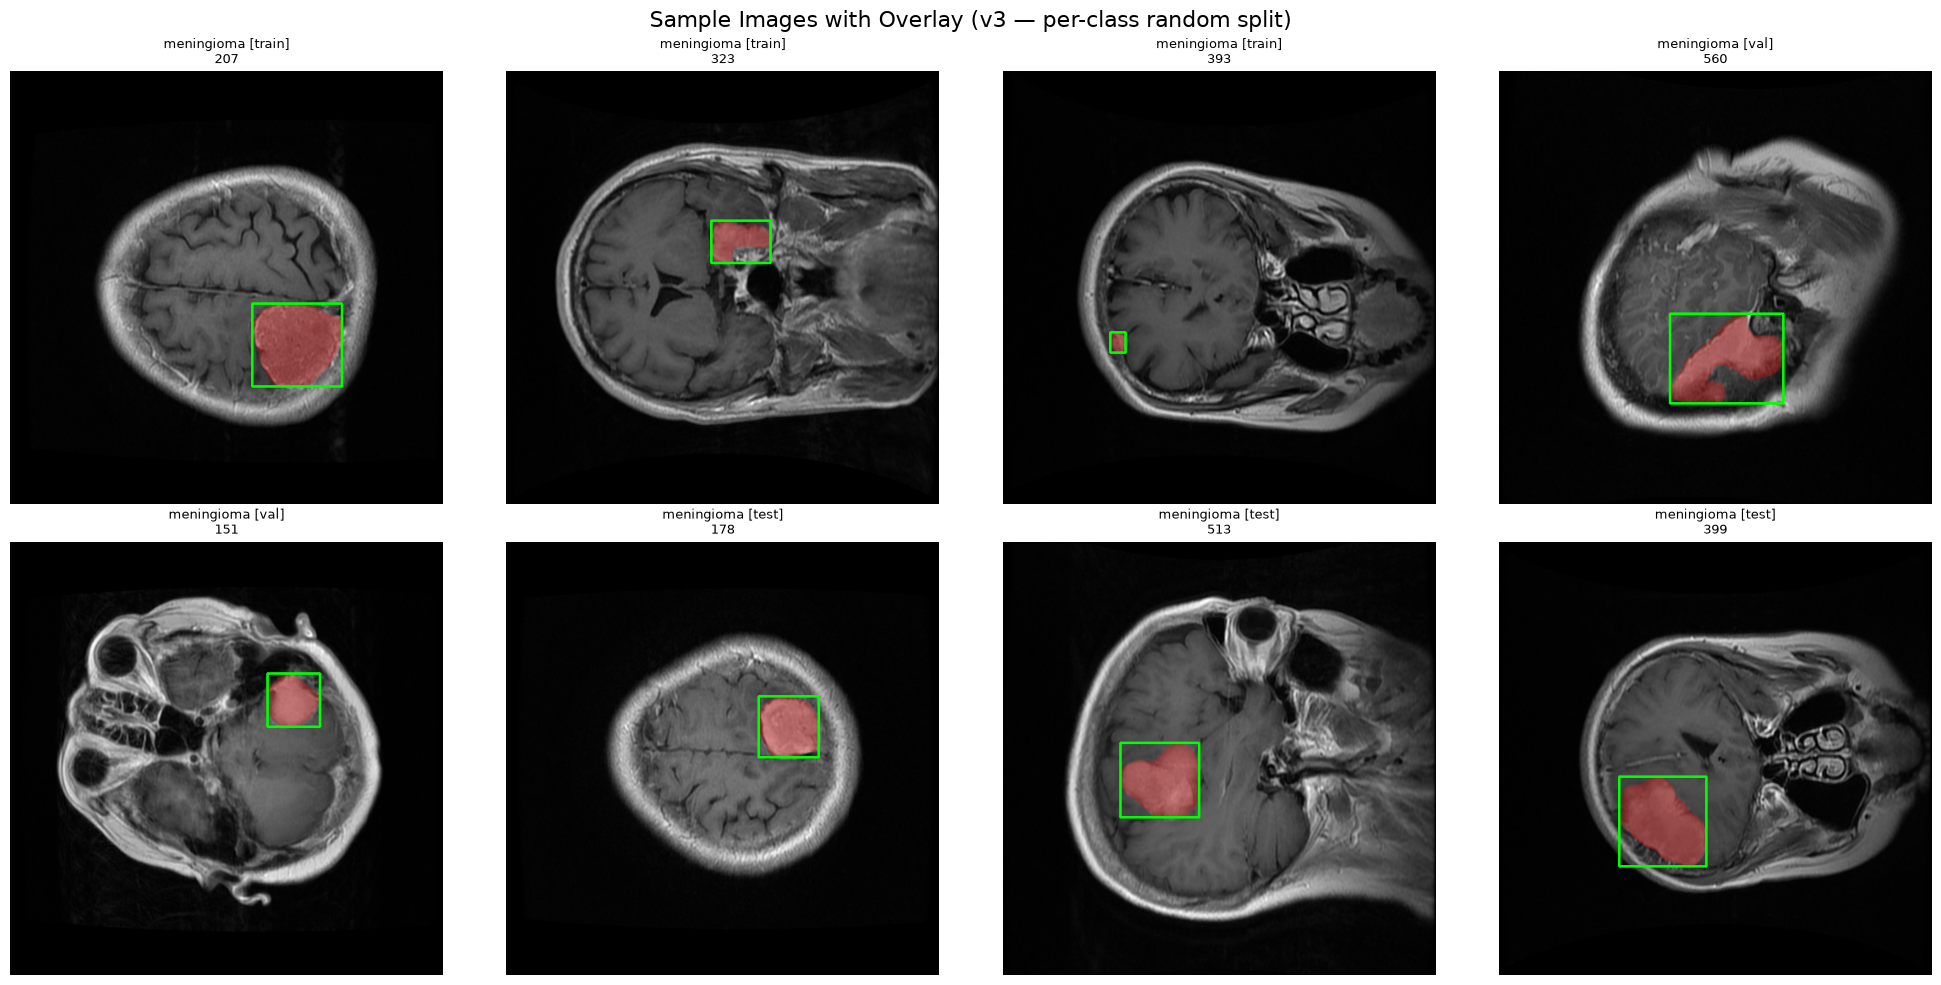

In [14]:
# === VISUAL SPOT-CHECK ===
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Sample Images with Overlay (v3 — per-class random split)', fontsize=16)

# Pick samples from each split
sample_indices = train_indices[:3] + val_indices[:2] + test_indices[:3]

for ax_idx, rec_idx in enumerate(sample_indices[:8]):
    r = records[rec_idx]
    fname = r['fname']
    split = split_assignment[rec_idx]
    
    # Load image
    img = cv2.imread(os.path.join(IMG_DIR, f'{fname}.png'), cv2.IMREAD_GRAYSCALE)
    img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    
    # Load mask
    mask = cv2.imread(os.path.join(MASK_DIR, f'{fname}.png'), cv2.IMREAD_GRAYSCALE)
    
    # Overlay mask in red
    overlay = img_color.copy()
    overlay[mask > 0] = [255, 0, 0]  # red
    blended = cv2.addWeighted(img_color, 0.7, overlay, 0.3, 0)
    
    # Draw bounding box from detection label
    det_path = os.path.join(DET_DIR, f'{fname}.txt')
    with open(det_path) as f:
        parts = f.read().strip().split()
    cls_id = int(parts[0])
    xc, yc, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
    h, w = img.shape
    x1 = int((xc - bw/2) * w)
    y1 = int((yc - bh/2) * h)
    x2 = int((xc + bw/2) * w)
    y2 = int((yc + bh/2) * h)
    cv2.rectangle(blended, (x1, y1), (x2, y2), (0, 255, 0), 2)
    
    row, col = divmod(ax_idx, 4)
    axes[row, col].imshow(blended)
    axes[row, col].set_title(f'{CLASS_NAMES[cls_id]} [{split}]\n{fname}', fontsize=9)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

## Summary

### v3 Split Strategy
- **Per-class random split** (no patient-wise stratification, no class balancing)  
- All **3,064** samples used  
- Split ratio: **95% train / 3% val / 2% test** per class  

### Output
- `dataset_v3/train/images/` + `dataset_v3/train/labels/`  
- `dataset_v3/val/images/` + `dataset_v3/val/labels/`  
- `dataset_v3/test/images/` + `dataset_v3/test/labels/`  
- `dataset_v3/data.yaml`  